In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error,classification_report
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.svm import SVR
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import mean_absolute_error

In [ ]:
# Load the CSV file
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Airline_customer_satisfaction.csv")
df
# Display shape before cleaning
print("Data shape before cleaning:", df.shape)

Data shape before cleaning: (129880, 22)


In [ ]:
# Display first and last 15 rows
print("First 15 rows:")
print(df.head(15))
print("\nLast 15 rows:")
print(df.tail(15))

First 15 rows:
   satisfaction   Customer Type  Age   Type of Travel     Class  \
0     satisfied  Loyal Customer   65  Personal Travel       Eco   
1     satisfied  Loyal Customer   47  Personal Travel  Business   
2     satisfied  Loyal Customer   15  Personal Travel       Eco   
3     satisfied  Loyal Customer   60  Personal Travel       Eco   
4     satisfied  Loyal Customer   70  Personal Travel       Eco   
5     satisfied  Loyal Customer   30  Personal Travel       Eco   
6     satisfied  Loyal Customer   66  Personal Travel       Eco   
7     satisfied  Loyal Customer   10  Personal Travel       Eco   
8     satisfied  Loyal Customer   56  Personal Travel  Business   
9     satisfied  Loyal Customer   22  Personal Travel       Eco   
10    satisfied  Loyal Customer   58  Personal Travel       Eco   
11    satisfied  Loyal Customer   34  Personal Travel       Eco   
12    satisfied  Loyal Customer   62  Personal Travel       Eco   
13    satisfied  Loyal Customer   35  Personal 

In [ ]:
print(df.columns)
# missing value
df.isnull().sum()



Index(['satisfaction', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Seat comfort', 'Departure/Arrival time convenient',
       'Food and drink', 'Gate location', 'Inflight wifi service',
       'Inflight entertainment', 'Online support', 'Ease of Online booking',
       'On-board service', 'Leg room service', 'Baggage handling',
       'Checkin service', 'Cleanliness', 'Online boarding',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes'],
      dtype='object')


,0
satisfaction,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Seat comfort,0
Departure/Arrival time convenient,0
Food and drink,0
Gate location,0


In [ ]:
#check duplicate value
df.duplicated().sum()


np.int64(0)

In [ ]:
df['Customer Type'].unique()


array(['Loyal Customer', 'disloyal Customer'], dtype=object)

In [ ]:

df['Type of Travel'].unique()

array(['Personal Travel', 'Business travel'], dtype=object)

In [ ]:
Class_mapping = {
    'Business': 0,
    'Eco': 1,
    'Eco Plus': 2
}
df['Class'] = df['Class'].map(Class_mapping)

In [ ]:
Customer_Type_mapping = {
    'Loyal Customer': 0,
    'disloyal Customer': 1,
}
df['Customer Type'] = df['Customer Type'].map(Customer_Type_mapping)

In [ ]:
Type_Travel_mapping = {
    'Personal Travel': 0,
    'Business travel': 1,

}
df['Type of Travel'] = df['Type of Travel'].map(Type_Travel_mapping)

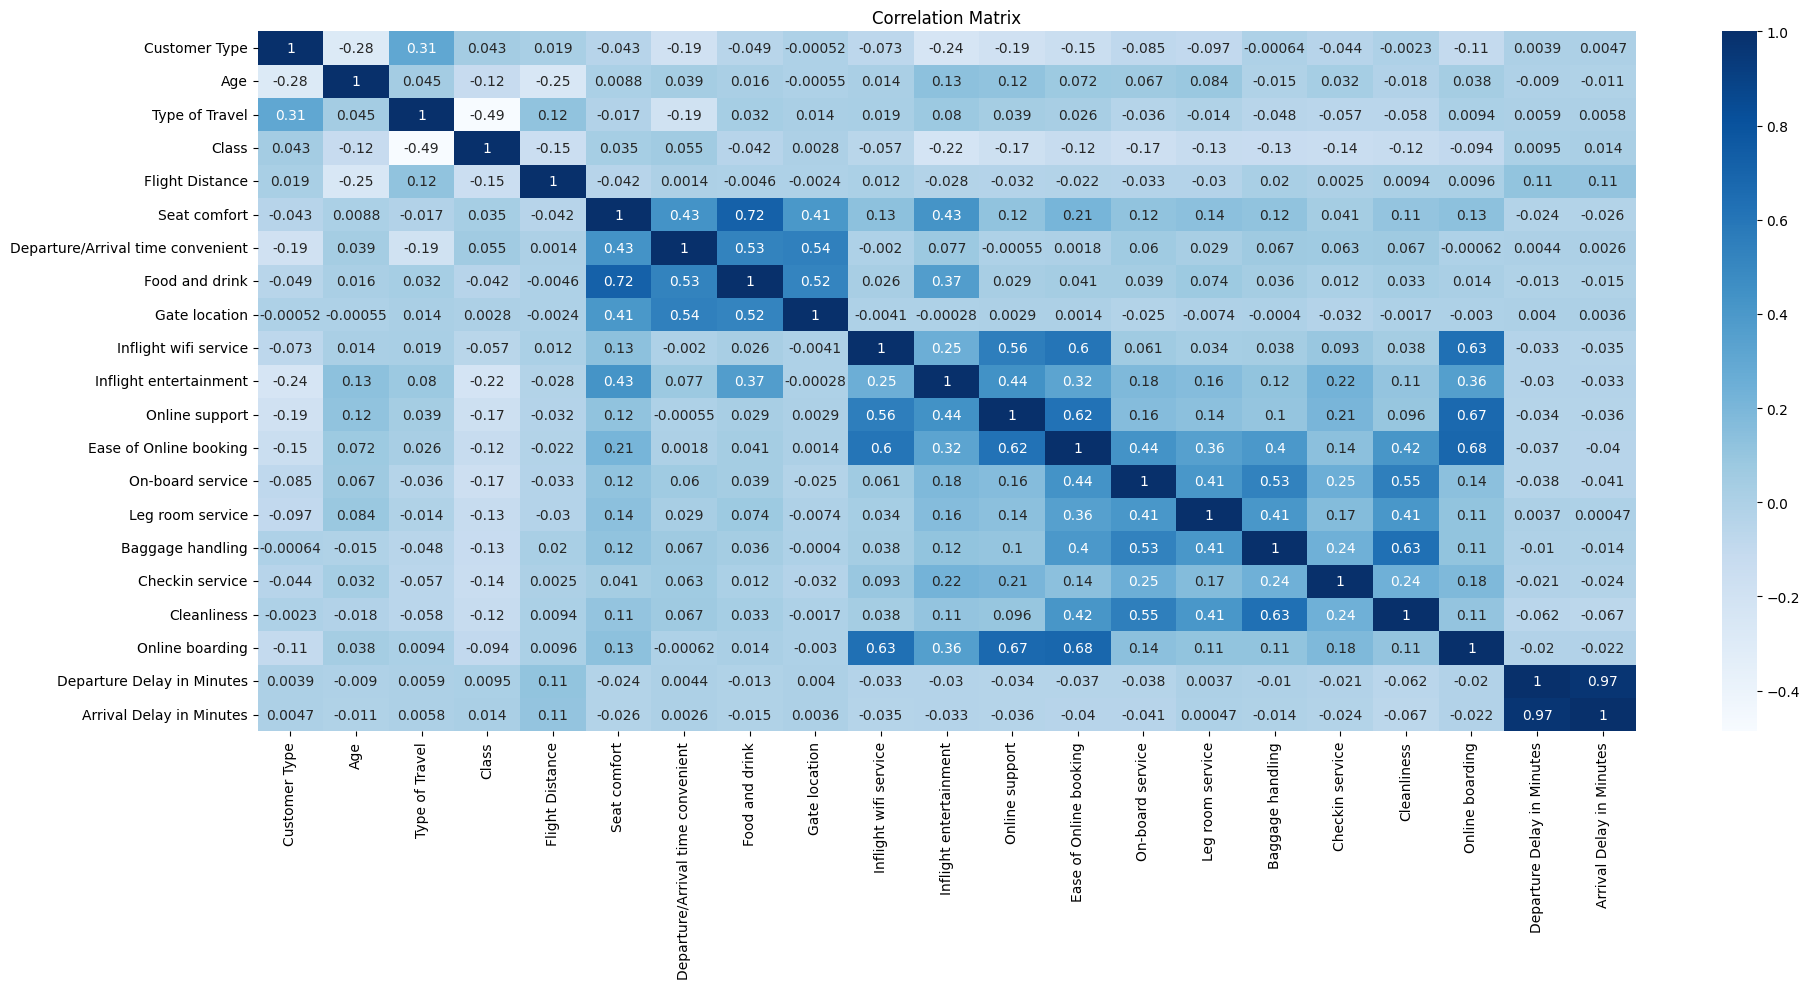

In [ ]:
#  Correlation Matrix
plt.figure(figsize=(20, 10))
sns.heatmap(df.corr(numeric_only=True),cmap='Blues', annot=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


In [ ]:
# Compute correlation matrix for numerical columns
correlation = df.corr(numeric_only=True)
mpg_corr = correlation['Customer Type'].sort_values(ascending=False)
print("Correlation of features with mpg:\n")
print(mpg_corr)

Correlation of features with mpg:

Customer Type                        1.000000
Type of Travel                       0.308236
Class                                0.042994
Flight Distance                      0.018938
Arrival Delay in Minutes             0.004730
Departure Delay in Minutes           0.003859
Gate location                       -0.000522
Baggage handling                    -0.000639
Cleanliness                         -0.002333
Seat comfort                        -0.042845
Checkin service                     -0.044353
Food and drink                      -0.048725
Inflight wifi service               -0.073400
On-board service                    -0.085433
Leg room service                    -0.097179
Online boarding                     -0.106394
Ease of Online booking              -0.149664
Departure/Arrival time convenient   -0.186053
Online support                      -0.186154
Inflight entertainment              -0.235757
Age                                 -0.284172

In [ ]:
df_cleaned = df.dropna()
y = df_cleaned['Customer Type']
X = df_cleaned.drop(columns=['Customer Type', 'satisfaction'])
# Train-Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.80, random_state=0
)
print("Training set (X_train):", X_train.shape)
print("Test set (X_test):", X_test.shape)
print("Training labels (y_train):", y_train.shape)
print("Test labels (y_test):", y_test.shape)

Training set (X_train): (25897, 20)
Test set (X_test): (103590, 20)
Training labels (y_train): (25897,)
Test labels (y_test): (103590,)


In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)

In [ ]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results:")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Linear Regression Results:
Mean Squared Error (MSE): 0.10
R² Score: 0.31


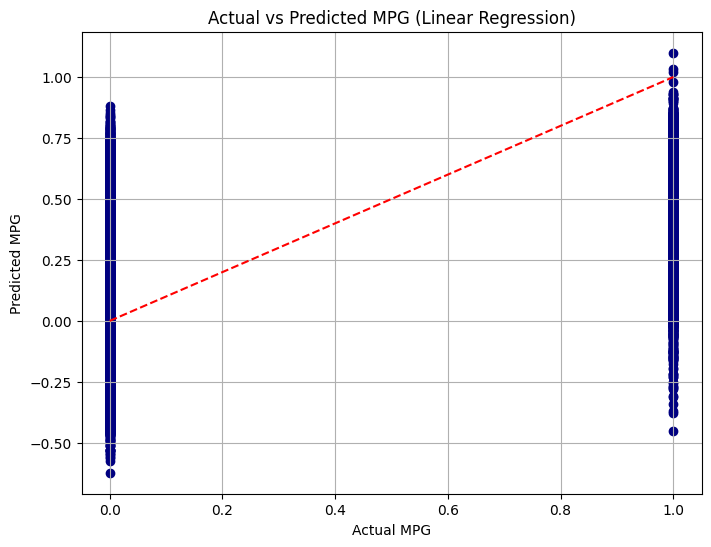

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='navy', alpha=1)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG (Linear Regression)")
plt.grid(True)
plt.show()
